# GameForge AI — Complete Kaggle Deformation Baseline

**Purpose:** run a complete, reproducible deformation-model baseline on Kaggle GPU, using the LPC action spritesheet dataset and the LPC four-view reference dataset.

This notebook includes dataset loading, sprite-cell extraction, synthetic deformation-pair generation, a PyTorch flow-deformation model, training, validation, sample visualizations, and checkpoint export.

**Scientific limitation:** the available datasets expose an `image` column but no verified same-character source/target pose pairs or 2-D keypoints. Therefore this notebook trains a **synthetic deformation baseline** using transformations generated from the sprites. It does not claim to learn true pose-conditioned animation. For real pose-conditioned training, verified animation pairs and pose annotations are still needed.

## Cell 1 — Runtime / GPU check

In [1]:
import sys, platform, os, random, math, json, shutil
from pathlib import Path
import numpy as np
import torch

print("Python:", sys.version)
print("Platform:", platform.platform())
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    torch.backends.cudnn.benchmark = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Platform: Linux-6.18.55+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cu128
CUDA: True
GPU: Tesla T4


## Cell 2 — Install/import required packages

In [2]:
# Kaggle normally has these already. Uncomment only if an import fails:
# %pip -q install datasets pillow matplotlib pandas scipy

from datasets import load_dataset
from PIL import Image, ImageDraw
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import matplotlib.pyplot as plt
import pandas as pd
from collections import Counter

WORK = Path("/kaggle/working/gameforge_deformation")
WORK.mkdir(parents=True, exist_ok=True)
print("Output directory:", WORK)

Output directory: /kaggle/working/gameforge_deformation


## Cell 3 — Load the two LPC datasets

In [3]:
ACTION_ID = "carlosuperb/lpc-action-pixel-art-diffusion"
REFERENCE_ID = "carlosuperb/lpc-4view-pixel-art-diffusion"

action_ds = load_dataset(ACTION_ID)
reference_ds = load_dataset(REFERENCE_ID)

print("Action rows:", len(action_ds["train"]), "columns:", action_ds["train"].column_names)
print("Reference rows:", len(reference_ds["train"]), "columns:", reference_ds["train"].column_names)
print("Action image:", action_ds["train"][0]["image"].size, action_ds["train"][0]["image"].mode)
print("Reference image:", reference_ds["train"][0]["image"].size, reference_ds["train"][0]["image"].mode)

README.md:   0%|          | 0.00/4.20k [00:00<?, ?B/s]

images/train.zip: reconstructing file:   0%|          |  0.00B / 2.74GB            

images/train.zip: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

README.md:   0%|          | 0.00/4.14k [00:00<?, ?B/s]

images/train.zip: reconstructing file:   0%|          |  0.00B /  278MB            

images/train.zip: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Action rows: 50000 columns: ['image']
Reference rows: 50000 columns: ['image']
Action image: (576, 768) RGBA
Reference image: (128, 128) RGBA


## Cell 4 — Preview images

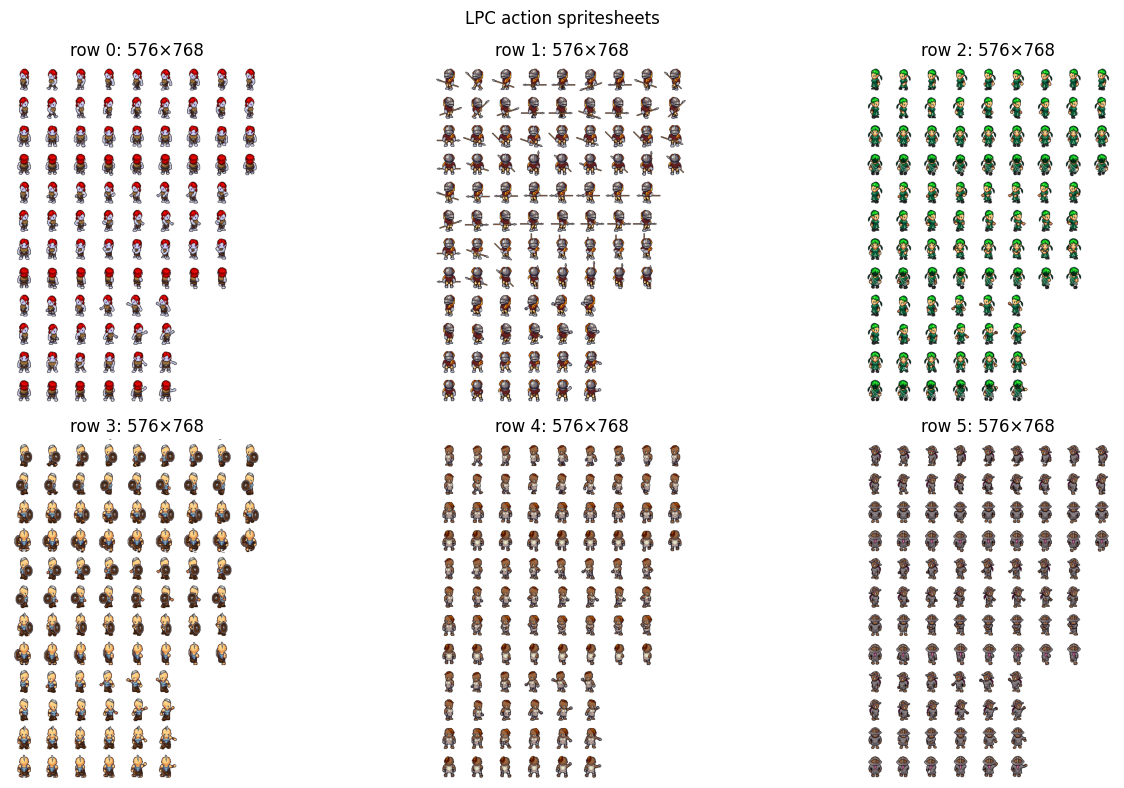

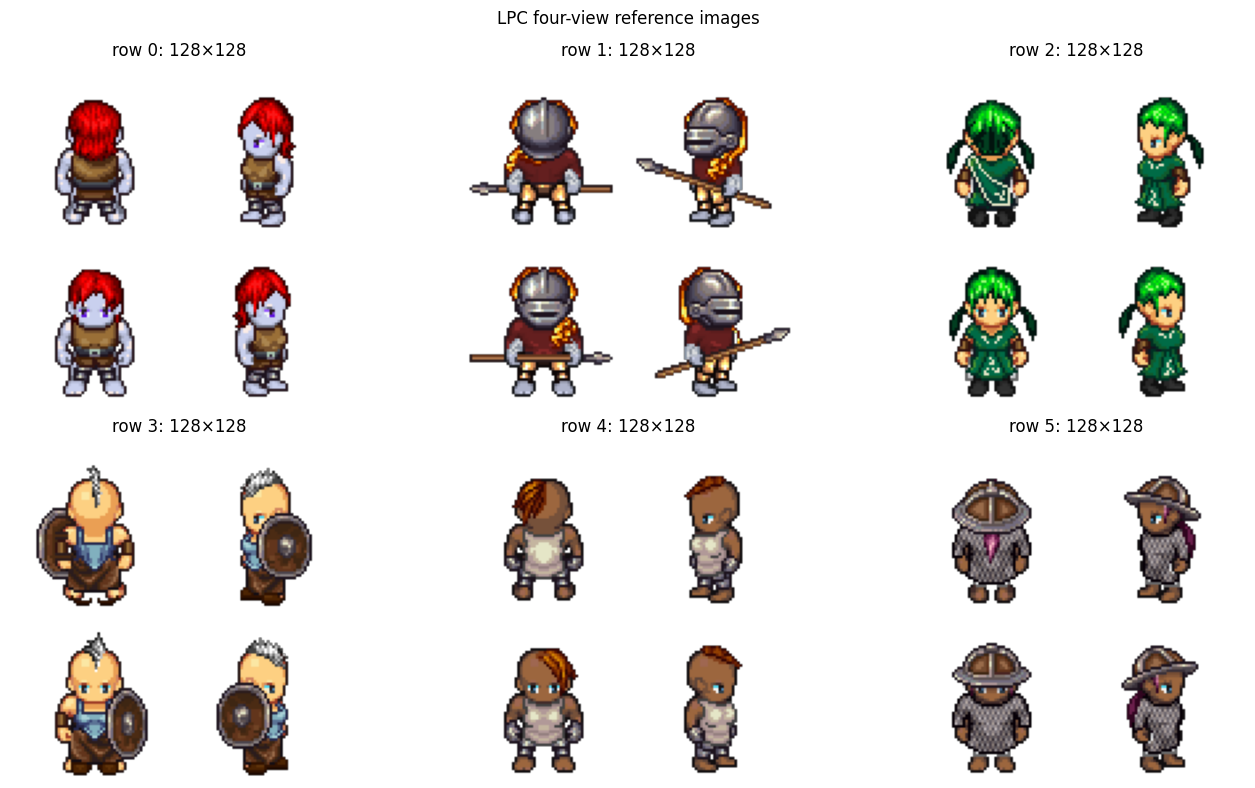

In [4]:
def preview_dataset(ds, title, count=6):
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    fig.suptitle(title)
    for i, ax in enumerate(axes.flat):
        im = ds["train"][i]["image"]
        ax.imshow(im)
        ax.set_title(f"row {i}: {im.width}×{im.height}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

preview_dataset(action_ds, "LPC action spritesheets")
preview_dataset(reference_ds, "LPC four-view reference images")

## Cell 5 — Extract candidate cells from action spritesheets

The known sample sheet is 576×768 and visually arranged as a grid. We start with a configurable 9×16 grid (64×48 cells), preview it, and save each cell. Check the preview: if the grid does not align with sprite cells, change `GRID_COLS` / `GRID_ROWS` before continuing.

In [5]:
GRID_COLS = 9
GRID_ROWS = 16
MAX_SHEETS = 250  # Raise after confirming grid alignment; limits initial runtime.
CELL_DIR = WORK / "sprite_cells"
CELL_DIR.mkdir(parents=True, exist_ok=True)

def split_grid(image, cols=GRID_COLS, rows=GRID_ROWS):
    im = image.convert("RGBA")
    cw, ch = im.width // cols, im.height // rows
    out = []
    for r in range(rows):
        for c in range(cols):
            box = (c*cw, r*ch, (c+1)*cw if c < cols-1 else im.width,
                   (r+1)*ch if r < rows-1 else im.height)
            crop = im.crop(box)
            if crop.getchannel("A").getbbox():
                out.append(crop)
    return out

# Save candidate cells from a subset of sheets.
saved = 0
for si in range(min(MAX_SHEETS, len(action_ds["train"]))):
    sheet = action_ds["train"][si]["image"]
    for ci, crop in enumerate(split_grid(sheet)):
        # Ignore nearly empty cells.
        alpha = np.asarray(crop.getchannel("A"))
        if (alpha > 0).sum() < 8:
            continue
        crop.save(CELL_DIR / f"sheet{si:05d}_cell{ci:03d}.png")
        saved += 1
print("Candidate sprite cells saved:", saved, "to", CELL_DIR)
print("Inspect the next cell before training.")

Candidate sprite cells saved: 31000 to /kaggle/working/gameforge_deformation/sprite_cells
Inspect the next cell before training.


## Cell 6 — Preview extracted cells

Cell files: 31000


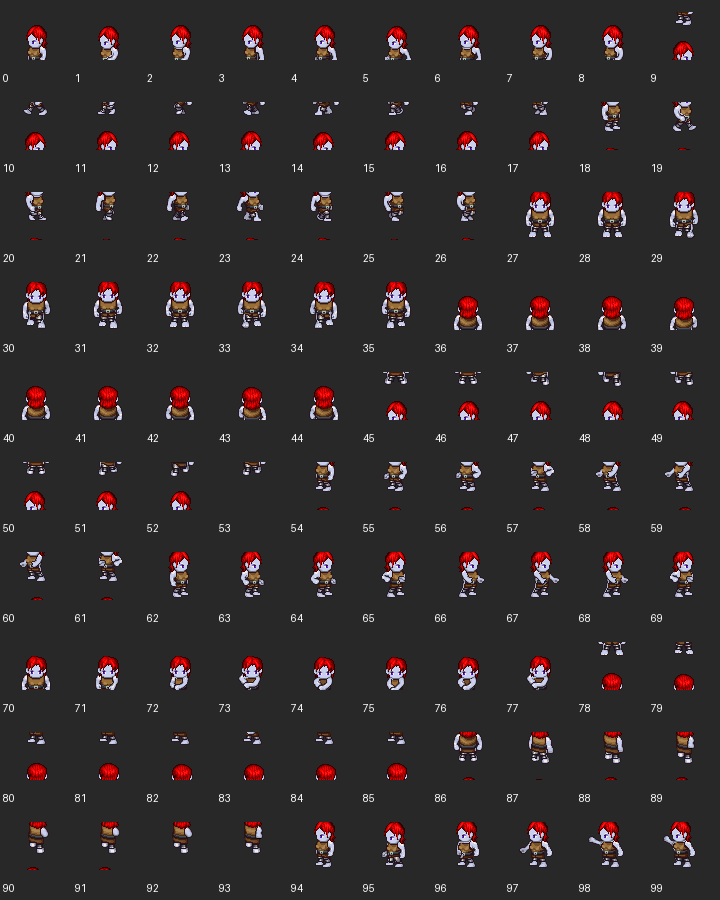

In [6]:
cell_paths = sorted(CELL_DIR.glob("*.png"))
print("Cell files:", len(cell_paths))
if cell_paths:
    n = min(100, len(cell_paths))
    cols = 10; rows = math.ceil(n/cols)
    tw, th = 72, 72
    sheet = Image.new("RGBA", (cols*tw, rows*(th+18)), (40,40,40,255))
    draw = ImageDraw.Draw(sheet)
    for i, p in enumerate(cell_paths[:n]):
        im = Image.open(p).convert("RGBA")
        im.thumbnail((tw-6, th-6), Image.Resampling.NEAREST)
        x = (i%cols)*tw + (tw-im.width)//2
        y = (i//cols)*(th+18) + (th-im.height)//2
        sheet.alpha_composite(im, (x,y))
        draw.text(((i%cols)*tw+3, (i//cols)*(th+18)+th), str(i), fill="white")
    display(sheet)

## Cell 7 — Define transformations and a synthetic training dataset

This generates reproducible affine-warp examples from individual sprite crops. Each sample uses a source crop and a randomly transformed target crop; the model learns to reproduce the synthetic target. This is useful for validating the deformation network and training loop, but it is **not equivalent to learning real animation poses**.

In [7]:
import torchvision.transforms.functional as TVF
from torchvision.transforms import InterpolationMode

IMAGE_SIZE = 64

def load_sprite_tensor(path, size=IMAGE_SIZE):
    im = Image.open(path).convert("RGBA")
    # Composite against transparent black for RGB training; alpha is retained separately for previews.
    im = im.resize((size, size), Image.Resampling.NEAREST)
    arr = np.asarray(im, dtype=np.float32) / 255.0
    rgb = torch.from_numpy(arr[:,:,:3].transpose(2,0,1).copy())
    alpha = torch.from_numpy(arr[:,:,3][None,:,:].copy())
    return rgb, alpha

class SyntheticDeformationDataset(Dataset):
    def __init__(self, paths, size=IMAGE_SIZE, repeats=8):
        self.paths = list(paths)
        self.size = size
        self.repeats = repeats
        if not self.paths:
            raise ValueError("No sprite cells available. Check Cell 5 grid settings.")
    def __len__(self):
        return len(self.paths) * self.repeats
    def __getitem__(self, idx):
        path = self.paths[idx % len(self.paths)]
        src, alpha = load_sprite_tensor(path, self.size)
        # Deterministic per-index augmentation for reproducibility.
        g = torch.Generator().manual_seed(SEED + idx)
        angle = float(torch.empty(1).uniform_(-22, 22, generator=g).item())
        tx = float(torch.empty(1).uniform_(-0.12, 0.12, generator=g).item() * self.size)
        ty = float(torch.empty(1).uniform_(-0.12, 0.12, generator=g).item() * self.size)
        scale = float(torch.empty(1).uniform_(0.85, 1.15, generator=g).item())
        # Nearest interpolation keeps pixel-art edges crisp.
        target = TVF.affine(
            src, angle=angle, translate=[int(tx), int(ty)], scale=scale, shear=[0.0, 0.0],
            interpolation=InterpolationMode.NEAREST, fill=0
        ).clamp(0,1)
        # A two-channel spatial conditioning map encodes target displacement parameters.
        cond = torch.zeros(2, self.size, self.size)
        cond[0].fill_(tx / self.size)
        cond[1].fill_(ty / self.size)
        return {"source": src, "target": target, "condition": cond, "alpha": alpha}

if not cell_paths:
    raise RuntimeError("No sprite crops. Recheck GRID_COLS/GRID_ROWS and rerun Cells 5–6.")
synthetic_ds = SyntheticDeformationDataset(cell_paths, repeats=8)
print("Synthetic training examples:", len(synthetic_ds))
sample = synthetic_ds[0]
print({k: tuple(v.shape) for k,v in sample.items()})

Synthetic training examples: 248000
{'source': (3, 64, 64), 'target': (3, 64, 64), 'condition': (2, 64, 64), 'alpha': (1, 64, 64)}


## Cell 8 — Visualize a synthetic source/target pair

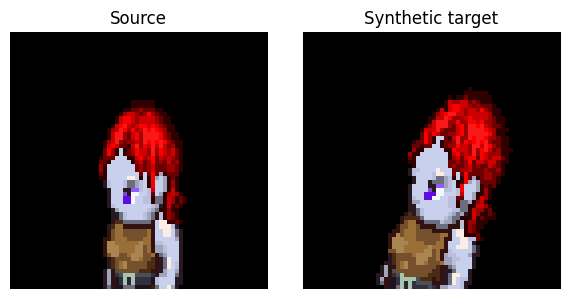

In [8]:
s = synthetic_ds[0]
fig, ax = plt.subplots(1, 2, figsize=(6,3))
ax[0].imshow(s["source"].permute(1,2,0).numpy()); ax[0].set_title("Source")
ax[1].imshow(s["target"].permute(1,2,0).numpy()); ax[1].set_title("Synthetic target")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## Cell 9 — Define the deformation model

In [9]:
def conv_block(cin, cout):
    groups = next((g for g in (8,4,2,1) if cout % g == 0), 1)
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1), nn.GroupNorm(groups, cout), nn.SiLU(),
        nn.Conv2d(cout, cout, 3, padding=1), nn.GroupNorm(groups, cout), nn.SiLU()
    )

class SpriteDeformationNet(nn.Module):
    """Predicts a dense normalized sampling flow from RGB source + 2-channel transform condition."""
    def __init__(self, base=32, max_flow=0.30):
        super().__init__()
        self.max_flow = max_flow
        self.enc0 = conv_block(5, base)
        self.down1 = nn.Conv2d(base, base*2, 4, 2, 1)
        self.enc1 = conv_block(base*2, base*2)
        self.down2 = nn.Conv2d(base*2, base*4, 4, 2, 1)
        self.mid = conv_block(base*4, base*4)
        self.up1 = nn.ConvTranspose2d(base*4, base*2, 4, 2, 1)
        self.dec1 = conv_block(base*4, base*2)
        self.up0 = nn.ConvTranspose2d(base*2, base, 4, 2, 1)
        self.dec0 = conv_block(base*2, base)
        self.flow_head = nn.Conv2d(base, 2, 3, padding=1)
        nn.init.zeros_(self.flow_head.weight)
        nn.init.zeros_(self.flow_head.bias)
    def forward(self, source, condition):
        x0 = self.enc0(torch.cat([source, condition], dim=1))
        x1 = self.enc1(self.down1(x0))
        x2 = self.mid(self.down2(x1))
        y1 = self.up1(x2)
        y1 = F.interpolate(y1, size=x1.shape[-2:], mode="nearest") if y1.shape[-2:] != x1.shape[-2:] else y1
        y1 = self.dec1(torch.cat([y1, x1], dim=1))
        y0 = self.up0(y1)
        y0 = F.interpolate(y0, size=x0.shape[-2:], mode="nearest") if y0.shape[-2:] != x0.shape[-2:] else y0
        flow = torch.tanh(self.flow_head(self.dec0(torch.cat([y0, x0], dim=1)))) * self.max_flow
        b, _, h, w = source.shape
        yy, xx = torch.meshgrid(
            torch.linspace(-1,1,h,device=source.device,dtype=source.dtype),
            torch.linspace(-1,1,w,device=source.device,dtype=source.dtype), indexing="ij"
        )
        grid = torch.stack([xx,yy],dim=-1).unsqueeze(0).expand(b,-1,-1,-1)
        warped = F.grid_sample(source, grid + flow.permute(0,2,3,1),
                               mode="nearest", padding_mode="zeros", align_corners=True)
        return warped, flow

model = SpriteDeformationNet().to(DEVICE)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Parameters: 848002


## Cell 10 — Train/validation split and loaders

In [10]:
n_val = max(1, int(0.1 * len(synthetic_ds)))
n_train = len(synthetic_ds) - n_val
train_ds, val_ds = random_split(
    synthetic_ds, [n_train, n_val], generator=torch.Generator().manual_seed(SEED)
)
BATCH_SIZE = 32 if torch.cuda.is_available() else 8
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2,
                          pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2,
                        pin_memory=torch.cuda.is_available())
print("Train:", len(train_ds), "Validation:", len(val_ds), "Batch:", BATCH_SIZE)

Train: 223200 Validation: 24800 Batch: 32


## Cell 11 — Train the deformation network

In [11]:
EPOCHS = 10  # Start small; increase to 30–50 after checking results.
LR = 2e-4
optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))
history = []
best_val = float("inf")
CHECKPOINT_DIR = WORK / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

for epoch in range(1, EPOCHS+1):
    model.train()
    train_sum, train_n = 0.0, 0
    for batch in train_loader:
        src = batch["source"].to(DEVICE, non_blocking=True)
        tgt = batch["target"].to(DEVICE, non_blocking=True)
        cond = batch["condition"].to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
            pred, flow = model(src, cond)
            loss = F.l1_loss(pred, tgt) + 0.005 * flow.abs().mean()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        train_sum += loss.item() * src.size(0); train_n += src.size(0)

    model.eval()
    val_sum, val_n = 0.0, 0
    with torch.no_grad():
        for batch in val_loader:
            src = batch["source"].to(DEVICE, non_blocking=True)
            tgt = batch["target"].to(DEVICE, non_blocking=True)
            cond = batch["condition"].to(DEVICE, non_blocking=True)
            pred, flow = model(src, cond)
            loss = F.l1_loss(pred, tgt) + 0.005 * flow.abs().mean()
            val_sum += loss.item() * src.size(0); val_n += src.size(0)

    train_loss = train_sum / max(train_n,1)
    val_loss = val_sum / max(val_n,1)
    history.append({"epoch":epoch,"train_l1":train_loss,"val_l1":val_loss})
    print(f"Epoch {epoch:02d}/{EPOCHS} — train {train_loss:.5f} — val {val_loss:.5f}")
    state = {"model_state_dict": model.state_dict(), "epoch": epoch, "val_loss": val_loss,
             "image_size": IMAGE_SIZE, "model_type": "SpriteDeformationNet",
             "note": "Trained on synthetic affine deformations; not real pose-paired animation."}
    torch.save(state, CHECKPOINT_DIR / "last.pt")
    if val_loss < best_val:
        best_val = val_loss
        torch.save(state, CHECKPOINT_DIR / "best.pt")

pd.DataFrame(history).to_csv(WORK / "training_history.csv", index=False)
print("Best checkpoint:", CHECKPOINT_DIR / "best.pt")

Epoch 01/10 — train 0.07780 — val 0.07778
Epoch 02/10 — train 0.07780 — val 0.07778
Epoch 03/10 — train 0.07780 — val 0.07778
Epoch 04/10 — train 0.07780 — val 0.07778
Epoch 05/10 — train 0.07780 — val 0.07778
Epoch 06/10 — train 0.07780 — val 0.07778
Epoch 07/10 — train 0.07780 — val 0.07778
Epoch 08/10 — train 0.07780 — val 0.07778
Epoch 09/10 — train 0.07780 — val 0.07778
Epoch 10/10 — train 0.07780 — val 0.07778
Best checkpoint: /kaggle/working/gameforge_deformation/checkpoints/best.pt


## Cell 12 — Plot training curves

,epoch,train_l1,val_l1
0,1,0.077795,0.07778
1,2,0.077795,0.07778
2,3,0.077795,0.07778
3,4,0.077795,0.07778
4,5,0.077795,0.07778
5,6,0.077795,0.07778
6,7,0.077795,0.07778
7,8,0.077795,0.07778
8,9,0.077795,0.07778
9,10,0.077795,0.07778


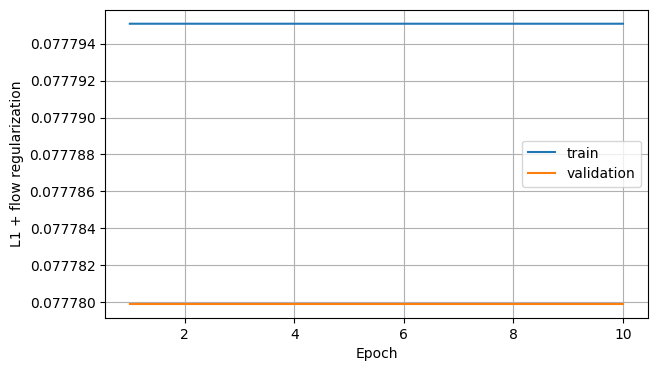

In [12]:
hist = pd.DataFrame(history)
display(hist)
plt.figure(figsize=(7,4))
plt.plot(hist["epoch"], hist["train_l1"], label="train")
plt.plot(hist["epoch"], hist["val_l1"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("L1 + flow regularization"); plt.legend(); plt.grid(True); plt.show()

## Cell 13 — Visualize model predictions

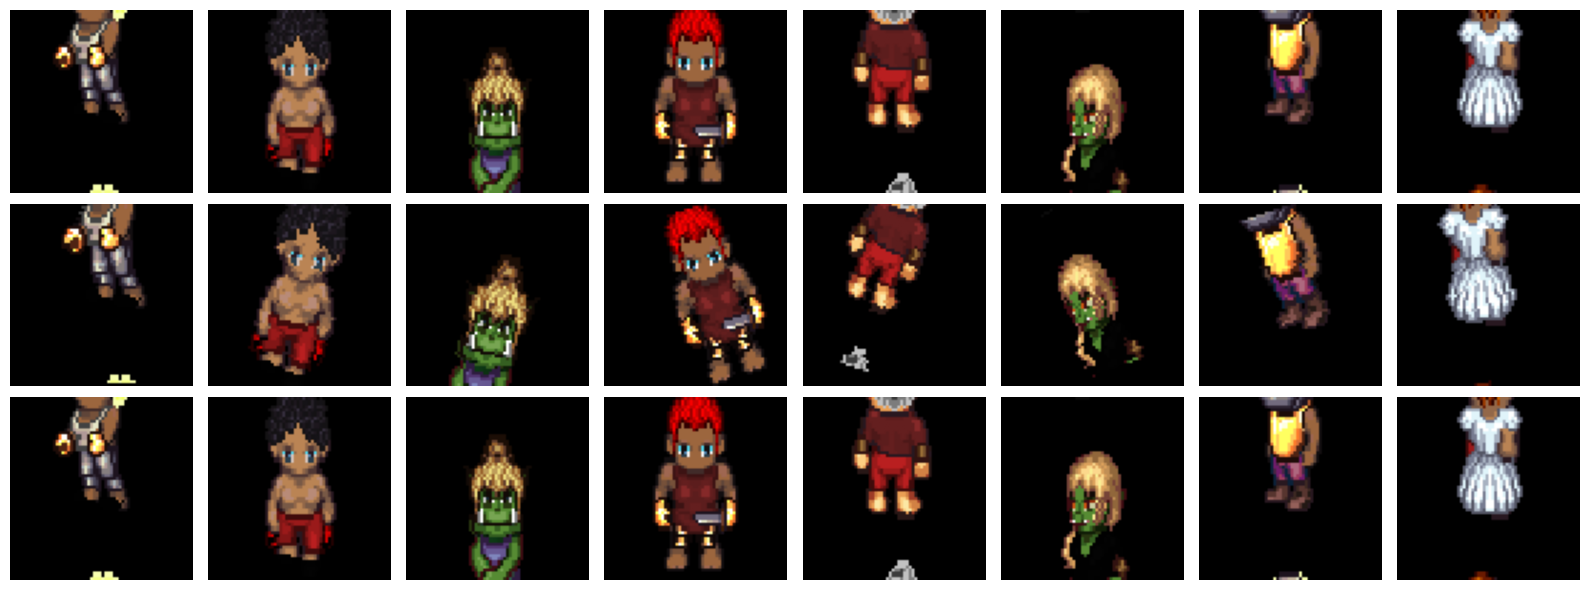

In [13]:
model.eval()
batch = next(iter(val_loader))
src = batch["source"][:8].to(DEVICE)
tgt = batch["target"][:8].to(DEVICE)
cond = batch["condition"][:8].to(DEVICE)
with torch.no_grad():
    pred, flow = model(src, cond)
src, tgt, pred = src.cpu(), tgt.cpu(), pred.cpu()
fig, axes = plt.subplots(3, 8, figsize=(16,6))
for i in range(min(8, src.shape[0])):
    axes[0,i].imshow(src[i].permute(1,2,0).clamp(0,1)); axes[0,i].axis("off")
    axes[1,i].imshow(tgt[i].permute(1,2,0).clamp(0,1)); axes[1,i].axis("off")
    axes[2,i].imshow(pred[i].permute(1,2,0).clamp(0,1)); axes[2,i].axis("off")
axes[0,0].set_ylabel("Source"); axes[1,0].set_ylabel("Target"); axes[2,0].set_ylabel("Predicted")
plt.tight_layout(); plt.show()

## Cell 14 — Save inference helper and model configuration

In [14]:
# Save a plain state dict plus a small config for application-side loading.
torch.save(model.state_dict(), WORK / "gameforge_sprite_deformation_state_dict.pt")
with open(WORK / "model_config.json", "w") as f:
    json.dump({
        "model_type": "SpriteDeformationNet",
        "image_size": IMAGE_SIZE,
        "base_channels": 32,
        "condition_channels": 2,
        "training_mode": "synthetic_affine_baseline",
        "limitations": "Not trained on verified pose pairs; use as baseline only."
    }, f, indent=2)

inference_code = r'''
import torch
import torch.nn.functional as F

def load_deformation_model(model_class, checkpoint_path, device="cpu"):
    ckpt = torch.load(checkpoint_path, map_location=device, weights_only=False)
    model = model_class().to(device)
    state = ckpt.get("model_state_dict", ckpt)
    model.load_state_dict(state)
    model.eval()
    return model

@torch.no_grad()
def deform_tensor(model, source_rgb, condition):
    # source_rgb: [B,3,H,W], condition: [B,2,H,W], both float tensors in [0,1]
    warped, flow = model(source_rgb, condition)
    return warped.clamp(0,1), flow
'''
(WORK / "inference_helper.py").write_text(inference_code)
print("Saved state dict, config, training history, and inference helper to", WORK)

Saved state dict, config, training history, and inference helper to /kaggle/working/gameforge_deformation


## Cell 15 — Zip outputs for download

In [15]:
EXPORT = Path("/kaggle/working/gameforge_deformation_baseline_artifacts.zip")
if EXPORT.exists():
    EXPORT.unlink()
shutil.make_archive(str(EXPORT.with_suffix("")), "zip", WORK)
print("Export ZIP:", EXPORT)
print("Files:")
for p in sorted(WORK.rglob("*")):
    if p.is_file():
        print(p.relative_to(WORK), f"({p.stat().st_size:,} bytes)")

Export ZIP: /kaggle/working/gameforge_deformation_baseline_artifacts.zip
Files:
checkpoints/best.pt (3,405,797 bytes)
checkpoints/last.pt (3,405,797 bytes)
gameforge_sprite_deformation_state_dict.pt (3,410,765 bytes)
inference_helper.py (579 bytes)
model_config.json (238 bytes)
sprite_cells/sheet00000_cell000.png (1,202 bytes)
sprite_cells/sheet00000_cell001.png (1,177 bytes)
sprite_cells/sheet00000_cell002.png (1,194 bytes)
sprite_cells/sheet00000_cell003.png (1,205 bytes)
sprite_cells/sheet00000_cell004.png (1,266 bytes)
sprite_cells/sheet00000_cell005.png (1,264 bytes)
sprite_cells/sheet00000_cell006.png (1,256 bytes)
sprite_cells/sheet00000_cell007.png (1,260 bytes)
sprite_cells/sheet00000_cell008.png (1,232 bytes)
sprite_cells/sheet00000_cell009.png (1,112 bytes)
sprite_cells/sheet00000_cell010.png (1,186 bytes)
sprite_cells/sheet00000_cell011.png (1,176 bytes)
sprite_cells/sheet00000_cell012.png (1,087 bytes)
sprite_cells/sheet00000_cell013.png (1,157 bytes)
sprite_cells/sheet000

## Interpretation / next step

This gives you a runnable deformation-model training baseline and exported checkpoint. The model learns synthetic affine warps, not character anatomy or real action transitions. For the final GameForge AI feature, replace the synthetic dataset with verified same-character animation pairs and matching pose/keypoint annotations, then train/evaluate against those real targets. Do not report synthetic validation loss as proof of animation quality.